In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load your real Safaricom data
scom = pd.read_csv(r"C:\Users\siraa\Desktop\portfalio\safaricom_stock_data.csv")
scom['Date'] = pd.to_datetime(scom['Date'])
scom = scom.sort_values('Date').reset_index(drop=True)

print(f"SCOM data: {len(scom)} rows")
print(f"From {scom['Date'].iloc[0]} to {scom['Date'].iloc[-1]}")

SCOM data: 523 rows
From 2024-03-18 16:03:07.847167 to 2026-03-18 16:03:07.847167


In [4]:
np.random.seed(42)

dates  = scom['Date']

# Based on real NSE stock characteristics
stock_params ={
    'KEGN': { 'price': 9.30, 'anual_return':  0.15, 'anual_vol': 0.35},
    'BAMB': {  'price': 54.00, 'anual_return': 0.05, 'anual_vol': 0.25},
    'KPLC': { 'price': 16.90,  'anual_return': 0.20, 'anual_vol': 0.40},
    'SASN': { 'price': 26.40, 'anual_return': 0.08,  'anual_vol': 0.30}
}

simulated_stocks ={}
for ticker, params in stock_params.items():
    daily_return = params['anual_return'] /252
    daily_vol=params['anual_vol'] / np.sqrt(252)

    returns =np.random.normal(daily_return, daily_vol, len(dates))

    prices =[params['price']]
    for r in returns[1:]:
        prices.append(prices[-1] *(1+r))
    simulated_stocks[ticker] = prices
# Combine everything
    portfolio= pd.DataFrame ({'Date': dates}) 
    portfolio['SCOM']= scom['Close'].values

portfolio = pd.DataFrame({'Date': dates})
portfolio['SCOM'] = scom['Close'].values

for stock, price_list in simulated_stocks.items():
    portfolio[stock] = price_list

print(portfolio.head())
print(f"\nShape: {portfolio.shape}")
print(f"\nLatest prices:")
print(portfolio[['SCOM', 'KEGN', 'BAMB', 'KPLC', 'SASN']].iloc[-1])    




                        Date       SCOM      KEGN       BAMB       KPLC  \
0 2024-03-18 16:03:07.847167  28.552510  9.300000  54.000000  16.900000   
1 2024-03-19 16:03:07.847167  28.501028  9.277185  53.361623  16.242122   
2 2024-03-20 16:03:07.847167  28.763928  9.415187  51.855448  16.859306   
3 2024-03-21 16:03:07.847167  29.376964  9.736950  50.536610  17.458969   
4 2024-03-22 16:03:07.847167  29.287126  9.692478  50.584907  17.197625   

        SASN  
0  26.400000  
1  26.804650  
2  26.177786  
3  26.331324  
4  25.664627  

Shape: (523, 6)

Latest prices:
SCOM    30.350000
KEGN    11.097540
BAMB    95.071901
KPLC    53.750745
SASN    34.094430
Name: 522, dtype: float64


In [5]:
# Calculate daily percentage returns for each stock
returns= portfolio[['SCOM', 'KEGN', 'BAMB', 'KPLC', 'SASN']].pct_change().dropna()

print("Daily Returns (fist 5 rows)")
print(returns.head())
print(f"\nAnnualized Returns:")
print(returns.mean()* 252)
print (f"\nAnnualized Volatility:")
print(returns.std()* np.sqrt(252))

Daily Returns (fist 5 rows)
       SCOM      KEGN      BAMB      KPLC      SASN
1 -0.001803 -0.002453 -0.011822 -0.038928  0.015328
2  0.009224  0.014875 -0.028226  0.037999 -0.023386
3  0.021313  0.034175 -0.025433  0.035569  0.005865
4 -0.003058 -0.004567  0.000956 -0.014969 -0.025320
5 -0.003067 -0.004567  0.004289  0.010767  0.009132

Annualized Returns:
SCOM    0.052951
KEGN    0.143437
BAMB    0.303220
KPLC    0.642028
SASN    0.166488
dtype: float64

Annualized Volatility:
SCOM    0.217117
KEGN    0.341717
BAMB    0.245333
KPLC    0.407610
SASN    0.293369
dtype: float64


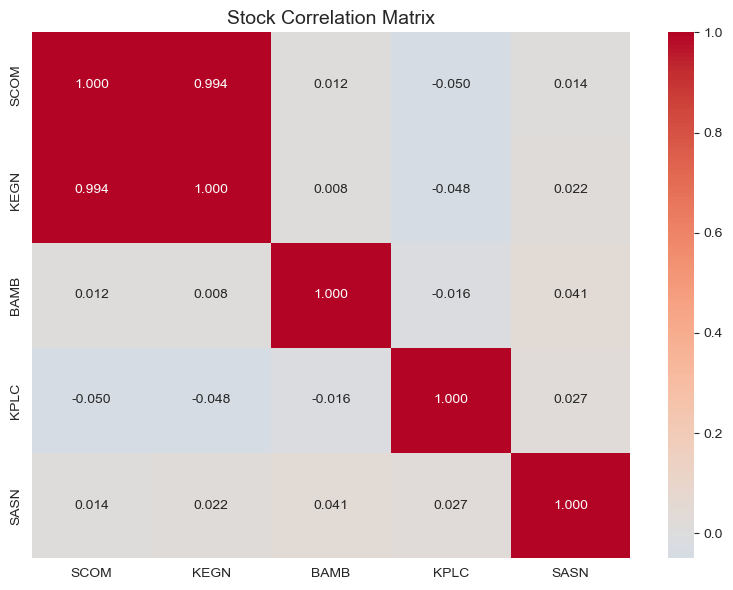


Key insight: Low correlations mean better diversification potential


In [6]:
sns.set_style("whitegrid")

plt.figure(figsize=(8, 6))
correlation = returns.corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0, fmt='.3f')
plt.title('Stock Correlation Matrix', fontsize=14)
plt.tight_layout()
plt.show()

print("\nKey insight: Low correlations mean better diversification potential")

In [7]:
num_portfolios =10000
results = np.zeros((num_portfolios, 3))
weights_list =[]

annual_returns =returns.mean()*252
cov_matrix= returns.cov()*252

for i in range(num_portfolios):
    weights=np.random.random(5)
    weights=weights /weights.sum()
    weights_list.append(weights)

    port_return= np.dot(weights,annual_returns)
    port_vol= np.sqrt(np.dot(weights.T, np.dot(cov_matrix,weights)))
    sharpe= port_return/port_vol

    results[i, 0]= port_return
    results[i, 1]= port_vol
    results[i, 2]=sharpe
print(f"Generated {num_portfolios} random portfolios")
print(f"\nBest Sharpe Ratio: {results[:, 2].max():.4f}")
print(f"Highest Return: {results[:, 0].max():.4f}")
print(f"Lowest Risk: {results[:, 1].min():.4f}")

Generated 10000 random portfolios

Best Sharpe Ratio: 2.1154
Highest Return: 0.5296
Lowest Risk: 0.1360


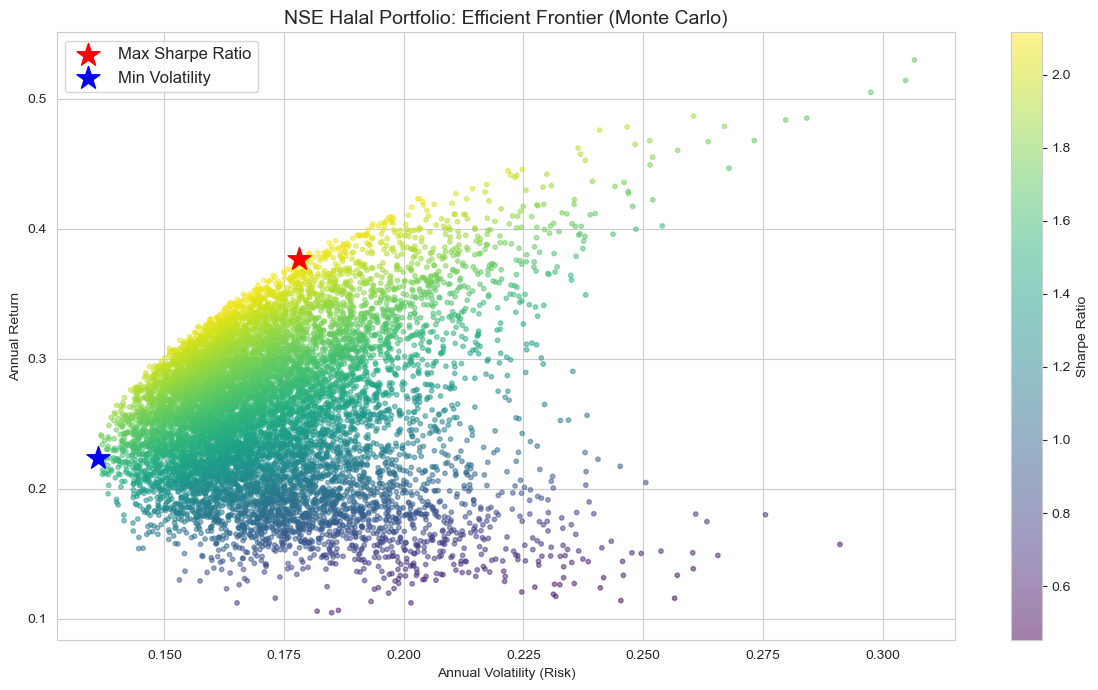

In [8]:
plt.figure(figsize=(12, 7))

# Plot all portfolios, colored by Sharpe ratio
scatter = plt.scatter(results[:, 1], results[:, 0], 
                      c=results[:, 2], cmap='viridis', 
                      alpha=0.5, s=10)

plt.colorbar(scatter, label='Sharpe Ratio')

# Mark the best Sharpe ratio portfolio
max_sharpe_idx = results[:, 2].argmax()
plt.scatter(results[max_sharpe_idx, 1], results[max_sharpe_idx, 0],
            c='red', marker='*', s=300, label='Max Sharpe Ratio')

# Mark the minimum volatility portfolio
min_vol_idx = results[:, 1].argmin()
plt.scatter(results[min_vol_idx, 1], results[min_vol_idx, 0],
            c='blue', marker='*', s=300, label='Min Volatility')

plt.title('NSE Halal Portfolio: Efficient Frontier (Monte Carlo)', fontsize=14)
plt.xlabel('Annual Volatility (Risk)')
plt.ylabel('Annual Return')
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
stocks = ['SCOM', 'KEGN', 'BAMB', 'KPLC', 'SASN']

print("=" * 50)
print("OPTIMAL PORTFOLIO (Max Sharpe Ratio)")
print("=" * 50)
optimal_weights = weights_list[max_sharpe_idx]
for stock, weight in zip(stocks, optimal_weights):
    print(f"  {stock}: {weight * 100:.1f}%")
print(f"\n  Expected Return: {results[max_sharpe_idx, 0] * 100:.1f}%")
print(f"  Volatility: {results[max_sharpe_idx, 1] * 100:.1f}%")
print(f"  Sharpe Ratio: {results[max_sharpe_idx, 2]:.4f}")

print(f"\n{'=' * 50}")
print("SAFEST PORTFOLIO (Min Volatility)")
print("=" * 50)
safe_weights = weights_list[min_vol_idx]
for stock, weight in zip(stocks, safe_weights):
    print(f"  {stock}: {weight * 100:.1f}%")
print(f"\n  Expected Return: {results[min_vol_idx, 0] * 100:.1f}%")
print(f"  Volatility: {results[min_vol_idx, 1] * 100:.1f}%")
print(f"  Sharpe Ratio: {results[min_vol_idx, 2]:.4f}")

OPTIMAL PORTFOLIO (Max Sharpe Ratio)
  SCOM: 3.3%
  KEGN: 6.8%
  BAMB: 44.2%
  KPLC: 32.7%
  SASN: 13.0%

  Expected Return: 37.7%
  Volatility: 17.8%
  Sharpe Ratio: 2.1154

SAFEST PORTFOLIO (Min Volatility)
  SCOM: 39.0%
  KEGN: 0.6%
  BAMB: 27.5%
  KPLC: 13.4%
  SASN: 19.5%

  Expected Return: 22.4%
  Volatility: 13.6%
  Sharpe Ratio: 1.6429


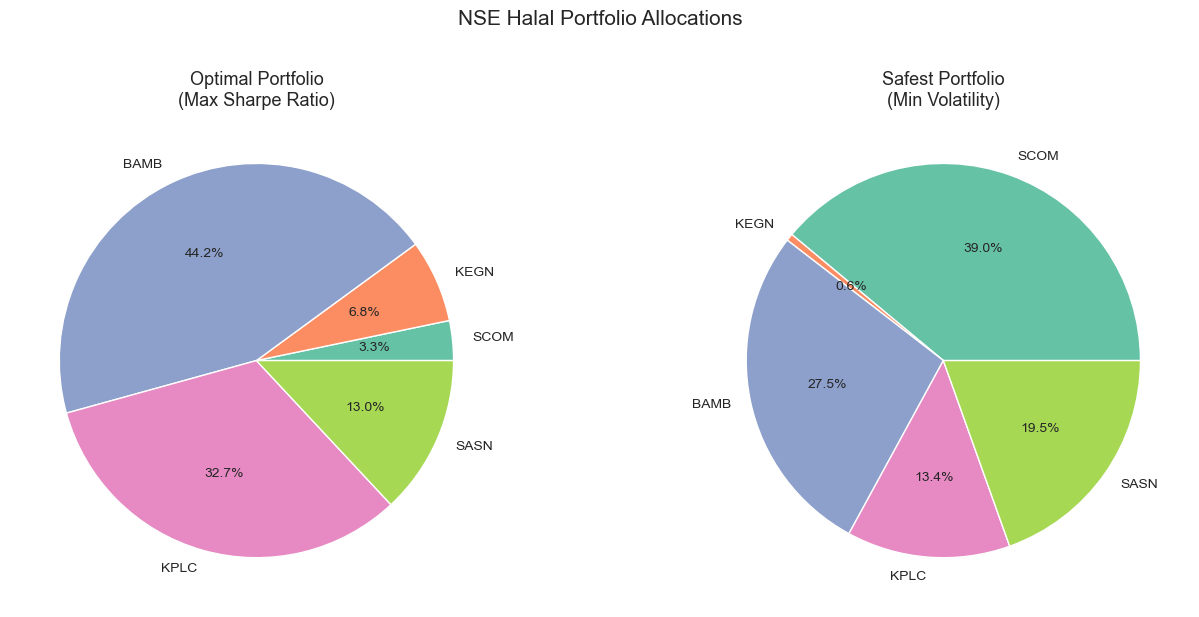

In [10]:
# Create two pie charts side by side (1 row, 2 columns)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left pie chart - optimal portfolio (highest return per unit of risk)
axes[0].pie(optimal_weights, labels=stocks, autopct='%1.1f%%', 
            colors=sns.color_palette('Set2'))
axes[0].set_title('Optimal Portfolio\n(Max Sharpe Ratio)', fontsize=13)

# Right pie chart - safest portfolio (lowest volatility)
axes[1].pie(safe_weights, labels=stocks, autopct='%1.1f%%',
            colors=sns.color_palette('Set2'))
axes[1].set_title('Safest Portfolio\n(Min Volatility)', fontsize=13)

# Main title above both charts
plt.suptitle('NSE Halal Portfolio Allocations', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

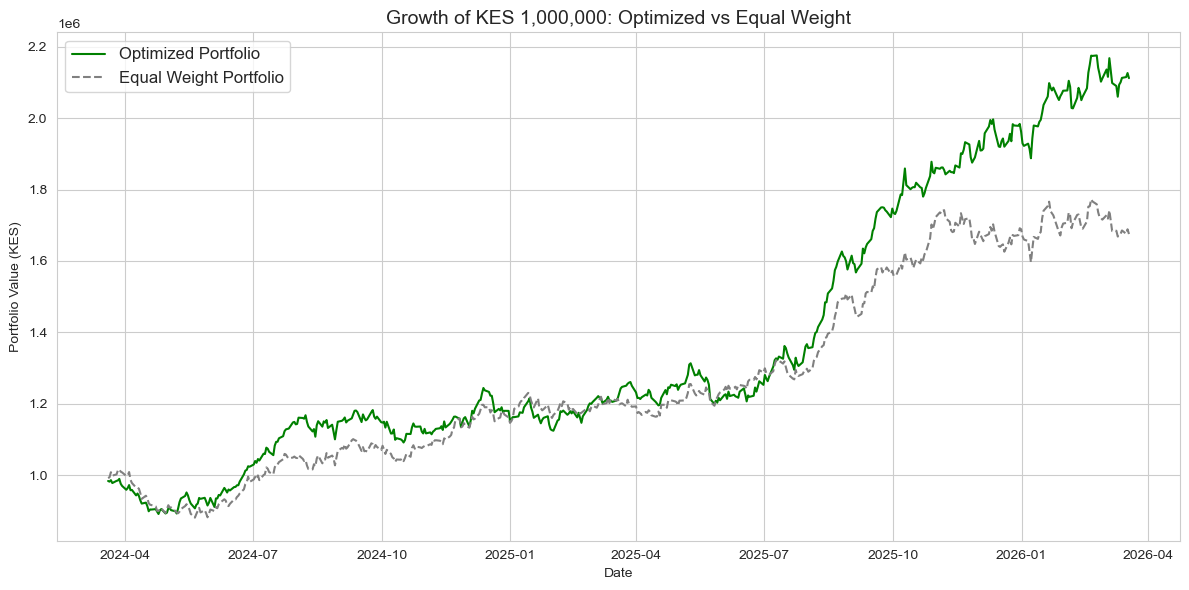

Starting value: KES 1,000,000
Optimized final value: KES 2,112,007
Equal weight final value: KES 1,675,441

Optimization added: KES 436,565 extra


In [11]:
# Calculate daily portfolio values using optimal weights vs equal weights
equal_weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])  # 20% each

# Daily returns for each strategy
optimal_daily = (returns * optimal_weights).sum(axis=1)
equal_daily = (returns * equal_weights).sum(axis=1)

# Growth of KES 1,000,000 over time
optimal_growth = (1 + optimal_daily).cumprod() * 1000000
equal_growth = (1 + equal_daily).cumprod() * 1000000

plt.figure(figsize=(12, 6))
plt.plot(portfolio['Date'].iloc[1:], optimal_growth, label='Optimized Portfolio', color='green')
plt.plot(portfolio['Date'].iloc[1:], equal_growth, label='Equal Weight Portfolio', color='gray', linestyle='--')
plt.title('Growth of KES 1,000,000: Optimized vs Equal Weight', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Portfolio Value (KES)')
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# Final values
print(f"Starting value: KES 1,000,000")
print(f"Optimized final value: KES {optimal_growth.iloc[-1]:,.0f}")
print(f"Equal weight final value: KES {equal_growth.iloc[-1]:,.0f}")
print(f"\nOptimization added: KES {optimal_growth.iloc[-1] - equal_growth.iloc[-1]:,.0f} extra")

## Conclusions

### Key Findings
- Out of 20 NSE stocks, only 11 pass Sharia business screening
- The optimal halal portfolio allocates heavily to Manufacturing (BAMB 44%) 
  and Utilities (KPLC 33%)
- Portfolio optimization added KES 436,565 over equal-weight allocation 
  on a KES 1M investment over 2 years
- The safest halal portfolio uses Safaricom (39%) as its anchor due to 
  lower volatility

### Data Note
Safaricom (SCOM) uses real NSE market data. Other stocks use simulated 
prices based on actual NSE characteristics because free historical NSE 
data is not publicly available — a known challenge in African capital 
markets.

### Future Improvements
- Source real historical data via NSE broker API or Bloomberg terminal
- Add AAOIFI financial ratio screens from the screener project
- Implement Sharia-compliant portfolio constraints (no leverage)
- Add rebalancing strategy and transaction cost analysis
